# Tutorial Notebook for IT_TF github repository

This notebook is WIP. Documentation will be added shortly. For now, we only go through regenerating the main figures in the paper

## Information Decay 
#### Starting from the ground up, we will generate 2 column MI/IC motifOrganisms encoding 1 bit of Total Information . We then bombard these motifs with mutations and compare how quickly their information decays. 

First, let's generate the motifPopulation with IC organisms

In [1]:
import json

In [2]:
#Writing proper parameters for IC population to JSON file
ICjsonfile_fig1 = {
	"Number_Organisms": 100,
	"Number_BindingSites": 128,
	"Length_BindingSites": 2,
	"GC_cont": 0.50,
	"Mutation_Rate": 0.01,
	"MI_mode": 1,
	"ReadInFiles": None,
	"Target_TI_Column": 0.5,
	"Prop_IC": 1,
	"ConstrictMode": "IC",
	"Eucledian_Thres": 0.05,
	"populationOutputFile": "./Output/Notebook/ICpop_fig1.json"
}  

with open("./src/settings_fitMotifPop.json", "w") as f:
    json.dump(ICjsonfile_fig1, f, indent = 3)



In [3]:
#We then generate the ICmotifPop
import src.fitMotifPopulation

src.fitMotifPopulation.main() 

We then run the information decay experiment

In [4]:
ICjsonfile_fig1_decay = {
    "Population_File":"./Output/Notebook/ICpop_fig1.json",
	"NumGenerationTerminate":1000,
	"lossOutputCSV": "./Output/Notebook/informationDecay_ICpop_fig1.json"	
}

with open("./src/settings_informationDecay.json", "w") as f:
    json.dump(ICjsonfile_fig1_decay, f, indent = 3)

In [5]:
#We then run the Information Decay experiment
import src.informationDecay

src.informationDecay.main()

version 0.1.8


Let's do the same with MI motifs

In [6]:
#Writing proper parameters for IC population to JSON file
MIjsonfile_fig1 = {
	"Number_Organisms": 100,
	"Number_BindingSites": 128,
	"Length_BindingSites": 2,
	"GC_cont": 0.50,
	"Mutation_Rate": 0.01,
	"MI_mode": 1,
	"ReadInFiles": None,
	"Target_TI_Column": 0.5,
	"Prop_IC": 0,
	"ConstrictMode": "MI",
	"Eucledian_Thres": 0.05,
	"populationOutputFile": "./Output/Notebook/MIpop_fig1.json"
}  

with open("./src/settings_fitMotifPop.json", "w") as f:
    json.dump(MIjsonfile_fig1, f, indent = 3)


In [7]:
#We then generate the ICmotifPop
import src.fitMotifPopulation

src.fitMotifPopulation.main() 

In [8]:
MIjsonfile_fig1_decay = {
    "Population_File":"./Output/Notebook/MIpop_fig1.json",
	"NumGenerationTerminate":1000,
	"lossOutputCSV": "./Output/Notebook/informationDecay_MIpop_fig1.json"	
}

with open("./src/settings_informationDecay.json", "w") as f:
    json.dump(MIjsonfile_fig1_decay, f, indent = 3)

In [9]:
#We then run the Information Decay experiment
import src.informationDecay

src.informationDecay.main()

Visualizing the results...

Figure(640x480)


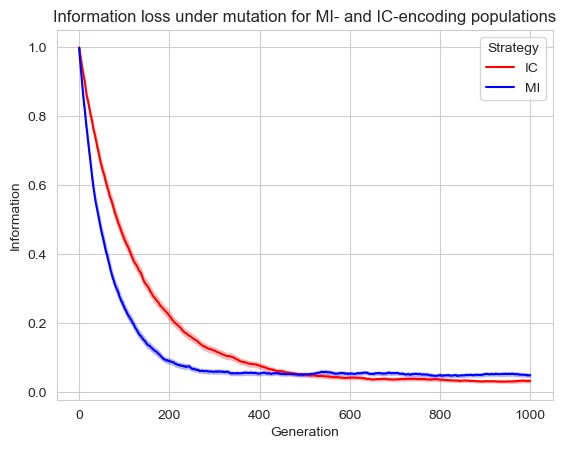

In [10]:
import src.figureFunctions

#Note: For the figure functions, order that we pass in the files is very important
print(src.figureFunctions.Figure1(["./Output/Notebook/informationDecay_ICpop_fig1.json", "./Output/Notebook/informationDecay_MIpop_fig1.json"])) #Figure1

##### The above figure seems to indicate IC motifs maintain their Information better after mutation than MI motifs. What about motifs in between 100% IC and 100% MI? We proceed to generate motifs that encode their Information somewhere between 100% IC and 100% MI and compare their mutational resillience 

In [13]:
#Defines encoding strategies. 0% IC 100% MI, 25% IC 75% MI, ...
propInformation = [0,0.25,0.50, 0.75,1]

#Repeats the process completed above for each strata between 100% IC and 100% MI in propInformation
for percentageIC in propInformation:

    #Generates json file and outputs it
    mixedjsonfile_fig1 = {
	"Number_Organisms": 100,
	"Number_BindingSites": 128,
	"Length_BindingSites": 2,
	"GC_cont": 0.50,
	"Mutation_Rate": 0.01,
	"MI_mode": 1,
	"ReadInFiles": None,
	"Target_TI_Column": 0.5,
	"Prop_IC": percentageIC,
	"ConstrictMode": "",
	"Eucledian_Thres": 0.05,
	"populationOutputFile": f"./Output/Notebook/mixedpop_{percentageIC}_fig1.json"
    
    }  
    with open("./src/settings_fitMotifPop.json", "w") as f:
        json.dump(mixedjsonfile_fig1, f, indent = 3)

    #Generates population
    src.fitMotifPopulation.main() 

    #Runs information decay experiment
    mixedjsonfile_fig1_decay = {
    "Population_File":f"./Output/Notebook/mixedpop_{percentageIC}_fig1.json",
	"NumGenerationTerminate":1000,
	"lossOutputCSV": f"./Output/Notebook/informationDecay_mixedpop_{percentageIC}_fig1.json"	
    }

    with open("./src/settings_informationDecay.json", "w") as f:
        json.dump(mixedjsonfile_fig1_decay, f, indent = 3)

    print(f"Done with {percentageIC}IC motifPopulation!") 
        
    src.informationDecay.main()

Done with 0IC motifPopulation!
Done with 0.25IC motifPopulation!
Done with 0.5IC motifPopulation!
Done with 0.75IC motifPopulation!
Done with 1IC motifPopulation!


Figure(640x480)


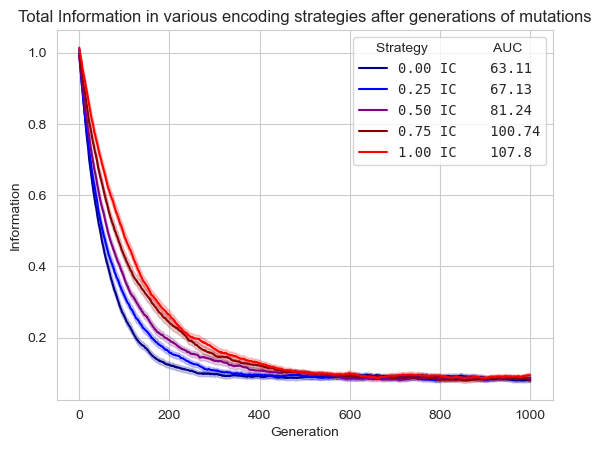

In [16]:
#Visualizing the results!
print(src.figureFunctions.SupplementaryFigure1([f"./Output/Notebook/informationDecay_mixedpop_{percentageIC}_fig1.json" for percentageIC in propInformation]))

##### The above figure seems to suggest that motifs that encode most of their information through IC are better positioned to maintain Information than motifs that trend more towards MI. We can see a clear improvement in mutational resilience going from MI to IC. 

##### A follow-up question. Transcription factors (TF) bind to sites that follow a certain motif pattern. Problems arise when these binding sites get mutated and start diverging from the pattern recognized by the TF. We can represent the original pattern as a probability frequency distribution and the mutated sites as another distribution. How does the divergence of IC binding sites from the motif after mutations compared to MI binding sites? To measure divergence, we employ Jennsen-Shannon Divergence

Figure(640x480)


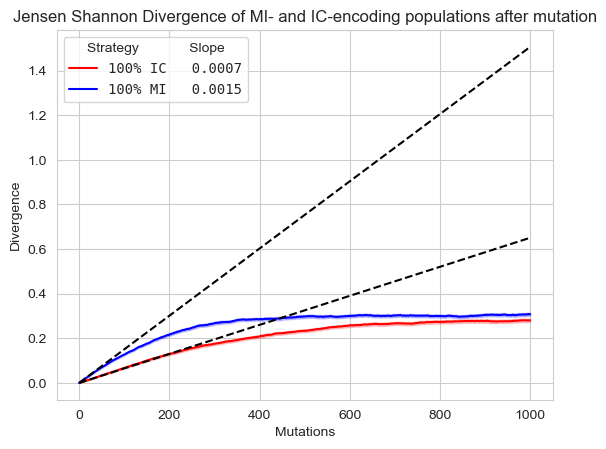

In [18]:
#Reusing the IC/MI informationDecay files we already generated, the JSD figure is visualized below
print(src.figureFunctions.SupplementaryFigure2(["./Output/Notebook/informationDecay_ICpop_fig1.json", "./Output/Notebook/informationDecay_MIpop_fig1.json"]))

##### Examining whether these mutational resillience properties remain true of IC and MI motifs as we vary Information Density...

In [24]:
#Defines different TI values for 2bp motif. 
TIpercol = [0.25,0.5,0.75,0.9] #Substitute 0.9 for 1
eucledian_thres = 0.1 #Higher thresholds leads to motifPopulations that are further from their goal but quickens computation

#Repeats for MI and IC
for strategy in ["IC","MI"]:
    #Variables for fitting motifPopulation
    propIC = 1 if strategy == "IC" else 0 
    
    #Repeats the process completed above for each information density value in the list above
    for TI in TIpercol:
    
        #Generates json file and outputs it
        jsonfile_fig2 = {
    	"Number_Organisms": 100,
    	"Number_BindingSites": 128,
    	"Length_BindingSites": 2,
    	"GC_cont": 0.50,
    	"Mutation_Rate": 0.01,
    	"MI_mode": 1,
    	"ReadInFiles": None,
    	"Target_TI_Column": TI,
    	"Prop_IC": propIC,
    	"ConstrictMode": strategy,
    	"Eucledian_Thres": eucledian_thres,
    	"populationOutputFile": f"./Output/Notebook/motifpop_{propIC}_{TI}_fig2.json"
        
        }  
        with open("./src/settings_fitMotifPop.json", "w") as f:
            json.dump(jsonfile_fig2, f, indent = 3)
    
        #Generates population
        src.fitMotifPopulation.main() 
    
        #Runs information decay experiment
        jsonfile_fig2_decay = {
        "Population_File":f"./Output/Notebook/motifpop_{propIC}_{TI}_fig2.json",
    	"NumGenerationTerminate":1000,
    	"lossOutputCSV": f"./Output/Notebook/informationDecay_{TI}{strategy}_fig2.json"	
        }
    
        with open("./src/settings_informationDecay.json", "w") as f:
            json.dump(jsonfile_fig2_decay, f, indent = 3)
                
        src.informationDecay.main()
    
    print(f"Done with {strategy} motifPopulations!") 


Done with IC motifPopulations!


KeyboardInterrupt: 

In [ ]:
print(src.figureFunctions.Figure2([f"./Output/Notebook/informationDecay_{TI}{strategy}_fig2.json"]))

##### Finally, we generate more realistically sized motifs and repeat the information decay experiments 

In [27]:
numOrgs = 20
motifLength = 12

#Writing proper parameters for IC population to JSON file
ICjsonfile_fig3 = {
	"Number_Organisms": numOrgs,
	"Number_BindingSites": 128,
	"Length_BindingSites": motifLength,
	"GC_cont": 0.50,
	"Mutation_Rate": 0.01,
	"MI_mode": 1,
	"ReadInFiles": None,
	"Target_TI_Column": 0.5,
	"Prop_IC": 1,
	"ConstrictMode": "IC",
	"Eucledian_Thres": 0.05,
	"populationOutputFile": "./Output/Notebook/ICpop_fig3.json"
}  

with open("./src/settings_fitMotifPop.json", "w") as f:
    json.dump(ICjsonfile_fig3, f, indent = 3)

#We then generate the ICmotifPop
src.fitMotifPopulation.main() 

ICjsonfile_fig3_decay = {
    "Population_File":"./Output/Notebook/ICpop_fig3.json",
	"NumGenerationTerminate":3000,
	"lossOutputCSV": "./Output/Notebook/informationDecay_ICpop_fig3.json"	
}

with open("./src/settings_informationDecay.json", "w") as f:
    json.dump(ICjsonfile_fig3_decay, f, indent = 3)

#We then run the Information Decay experiment
src.informationDecay.main()

In [30]:
#Writing proper parameters for IC population to JSON file
MIjsonfile_fig3 = {
	"Number_Organisms": numOrgs,
	"Number_BindingSites": 128,
	"Length_BindingSites": motifLength,
	"GC_cont": 0.50,
	"Mutation_Rate": 0.01,
	"MI_mode": 1,
	"ReadInFiles": None,
	"Target_TI_Column": 0.5,
	"Prop_IC": 0,
	"ConstrictMode": "MI",
	"Eucledian_Thres": 0.05,
	"populationOutputFile": "./Output/Notebook/MIpop_fig3.json"
}  

with open("./src/settings_fitMotifPop.json", "w") as f:
    json.dump(MIjsonfile_fig3, f, indent = 3)

#We then generate the ICmotifPop
src.fitMotifPopulation.main() 

MIjsonfile_fig3_decay = {
    "Population_File":"./Output/Notebook/MIpop_fig3.json",
	"NumGenerationTerminate":3000,
	"lossOutputCSV": "./Output/Notebook/informationDecay_MIpop_fig3.json"	
}

with open("./src/settings_informationDecay.json", "w") as f:
    json.dump(MIjsonfile_fig3_decay, f, indent = 3)

#We then run the Information Decay experiment
src.informationDecay.main()

Figure(640x480)


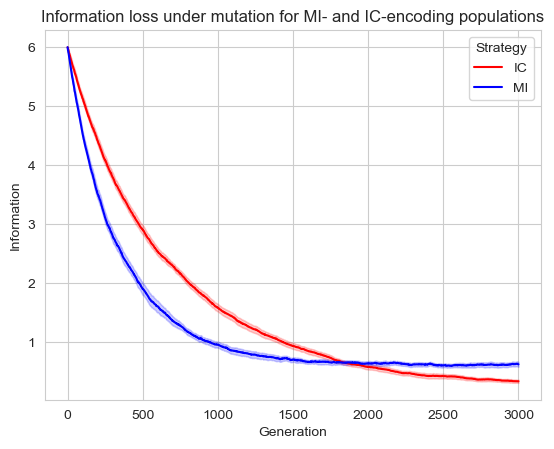

In [34]:
print(src.figureFunctions.Figure3(["./Output/Notebook/informationDecay_ICpop_fig3.json", "./Output/Notebook/informationDecay_MIpop_fig3.json"])) 

# Genome Search
We now further complicate our model by introducing a genome to explore interesting properties about IC/MI motifs. Specifically, we insert our motifs into a genome, introduce mutations to the genome, and measure how fast classification ability of binding sites from non-binding sites degrade. We measure classification ability through AUPRC and train kulakovsky model on the binding sites before mutation to classify binding sites and non-binding sites.  

First, we fit our motifs. We'll be visualizing AUPRC curves with different motif length

In [35]:
#Defines different length values
motifLengths = [10,12,14,16]
targetTI_column = 0.5

#Repeats for MI and IC
for strategy in ["IC","MI"]:
    #Variables for fitting motifPopulation
    propIC = 1 if strategy == "IC" else 0 
    
    #Repeats the process completed above for each motifLength above
    for L in motifLengths:
    
        #Generates json file and outputs it
        jsonfile_fig4 = {
    	"Number_Organisms": numOrgs,
    	"Number_BindingSites": 128,
    	"Length_BindingSites": L,
    	"GC_cont": 0.50,
    	"Mutation_Rate": 0.01,
    	"MI_mode": 1,
    	"ReadInFiles": None,
    	"Target_TI_Column": targetTI_column,
    	"Prop_IC": propIC,
    	"ConstrictMode": strategy,
    	"Eucledian_Thres": 0.05,
    	"populationOutputFile": f"./Output/Notebook/motifpop_{propIC}_{TI}_fig4.json"
        
        }  
        with open("./src/settings_fitMotifPop.json", "w") as f:
            json.dump(jsonfile_fig4, f, indent = 3)
    
        #Generates population
        src.fitMotifPopulation.main() 
    
    
    print(f"Done with {strategy} motifPopulations!") 


Done with IC motifPopulations!
Done with MI motifPopulations!
